# Oil.csv

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("../../data/raw")

oil = pd.read_csv(DATA_DIR / "oil.csv")

oil.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [2]:
oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB


In [3]:
oil["date"] = pd.to_datetime(oil["date"])

oil["dcoilwtico"] = pd.to_numeric(
    oil["dcoilwtico"],
    errors="coerce"
)

missing_oil = oil[oil["dcoilwtico"].isna()]

print("Total rows:", len(oil))
print("Missing values:", oil["dcoilwtico"].isna().sum())
print("Missing percentage:", round(
    oil["dcoilwtico"].isna().mean() * 100, 2
), "%")

missing_oil

Total rows: 1218
Missing values: 43
Missing percentage: 3.53 %


,date,dcoilwtico
0,2013-01-01,NaN
14,2013-01-21,NaN
34,2013-02-18,NaN
63,2013-03-29,NaN
104,2013-05-27,NaN
132,2013-07-04,NaN
174,2013-09-02,NaN
237,2013-11-28,NaN
256,2013-12-25,NaN
261,2014-01-01,NaN


In [4]:
print("Rentang tanggal:")
print("Awal:", oil["date"].min())
print("Akhir:", oil["date"].max())

print("\nMissing di awal:")
print(oil["dcoilwtico"].isna().iloc[:].cumprod().sum())

print("\nMissing di akhir:")
print(oil["dcoilwtico"].isna().iloc[::-1].cumprod().sum())

Rentang tanggal:
Awal: 2013-01-01 00:00:00
Akhir: 2017-08-31 00:00:00

Missing di awal:
1

Missing di akhir:
0


In [5]:
# Tampilkan seluruh tanggal yang memiliki missing value
missing_oil = oil.loc[
    oil["dcoilwtico"].isna(),
    ["date", "dcoilwtico"]
]

missing_oil

,date,dcoilwtico
0,2013-01-01,NaN
14,2013-01-21,NaN
34,2013-02-18,NaN
63,2013-03-29,NaN
104,2013-05-27,NaN
132,2013-07-04,NaN
174,2013-09-02,NaN
237,2013-11-28,NaN
256,2013-12-25,NaN
261,2014-01-01,NaN


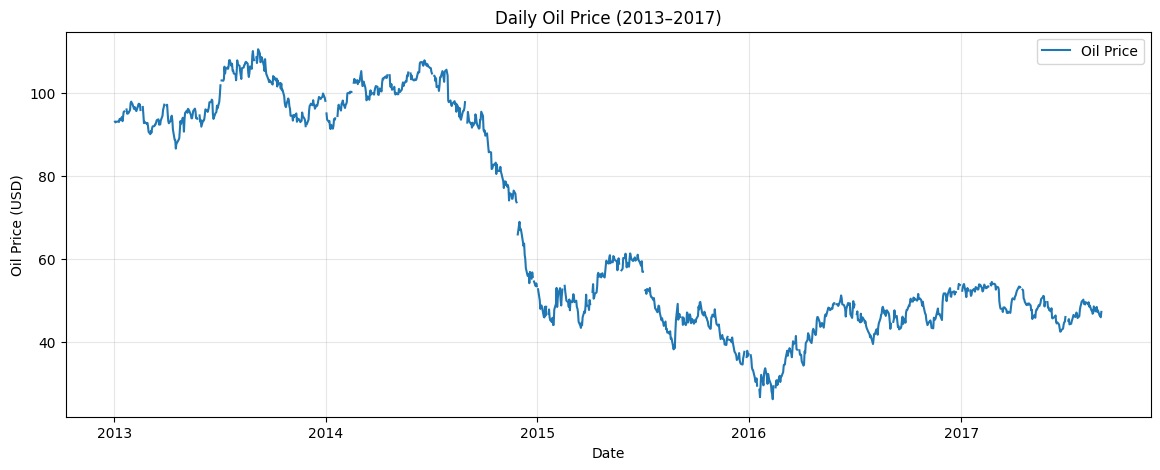

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    oil["date"],
    oil["dcoilwtico"],
    label="Oil Price"
)

plt.title("Daily Oil Price (2013–2017)")
plt.xlabel("Date")
plt.ylabel("Oil Price (USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [7]:
oil_clean = oil.copy()

oil_clean = oil_clean.sort_values("date")

oil_clean = oil_clean.set_index("date")

# Interpolasi berdasarkan waktu
oil_clean["dcoilwtico"] = (
    oil_clean["dcoilwtico"]
    .interpolate(method="time")
)

# Mengisi missing pertama menggunakan nilai terdekat setelahnya
oil_clean["dcoilwtico"] = (
    oil_clean["dcoilwtico"].bfill()
)

oil_clean = oil_clean.reset_index()

print("Missing sebelum:", oil["dcoilwtico"].isna().sum())
print("Missing sesudah:", oil_clean["dcoilwtico"].isna().sum())

Missing sebelum: 43
Missing sesudah: 0


In [8]:
oil_clean.loc[
    oil_clean["date"].isin(
        missing_oil["date"]
    ),
    ["date", "dcoilwtico"]
]

,date,dcoilwtico
0,2013-01-01,93.1400
14,2013-01-21,95.9700
34,2013-02-18,96.5050
63,2013-03-29,97.2050
104,2013-05-27,94.4475
132,2013-07-04,102.5050
174,2013-09-02,108.4975
237,2013-11-28,92.3000
256,2013-12-25,99.0250
261,2014-01-01,96.6550


# Train.csv

In [9]:
train = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["date"]
)

train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [10]:
train.info()

train[["sales", "onpromotion"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


,sales,onpromotion
count,3.000888e+06,3.000888e+06
mean,3.577757e+02,2.602770e+00
std,1.101998e+03,1.221888e+01
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.100000e+01,0.000000e+00
75%,1.958473e+02,0.000000e+00
max,1.247170e+05,7.410000e+02


In [11]:
monthly_sales = (
    train.groupby(train["date"].dt.to_period("M"))["sales"]
    .sum()
    .reset_index()
)

monthly_sales["date"] = monthly_sales["date"].astype(str)

monthly_sales.head()

,date,sales
0,2013-01,1.032762e+07
1,2013-02,9.658960e+06
2,2013-03,1.142850e+07
3,2013-04,1.099346e+07
4,2013-05,1.159770e+07


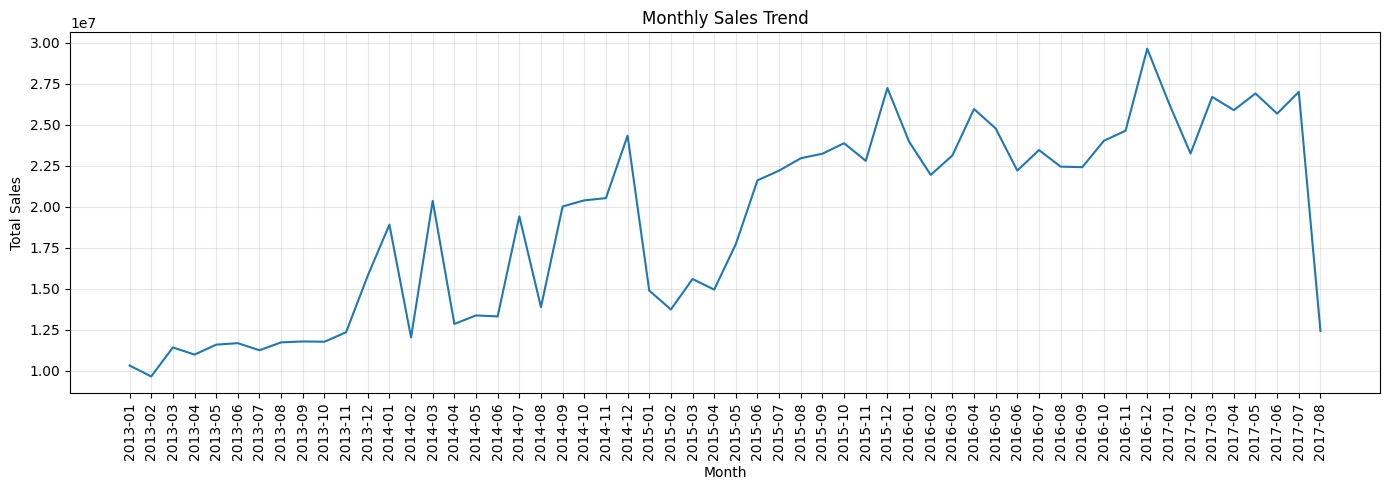

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales["date"],
    monthly_sales["sales"]
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
family_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

family_sales.head(10)

,family,sales
0,GROCERY I,3.434627e+08
1,BEVERAGES,2.169545e+08
2,PRODUCE,1.227047e+08
3,CLEANING,9.752129e+07
4,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
6,POULTRY,3.187600e+07
7,MEATS,3.108647e+07
8,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


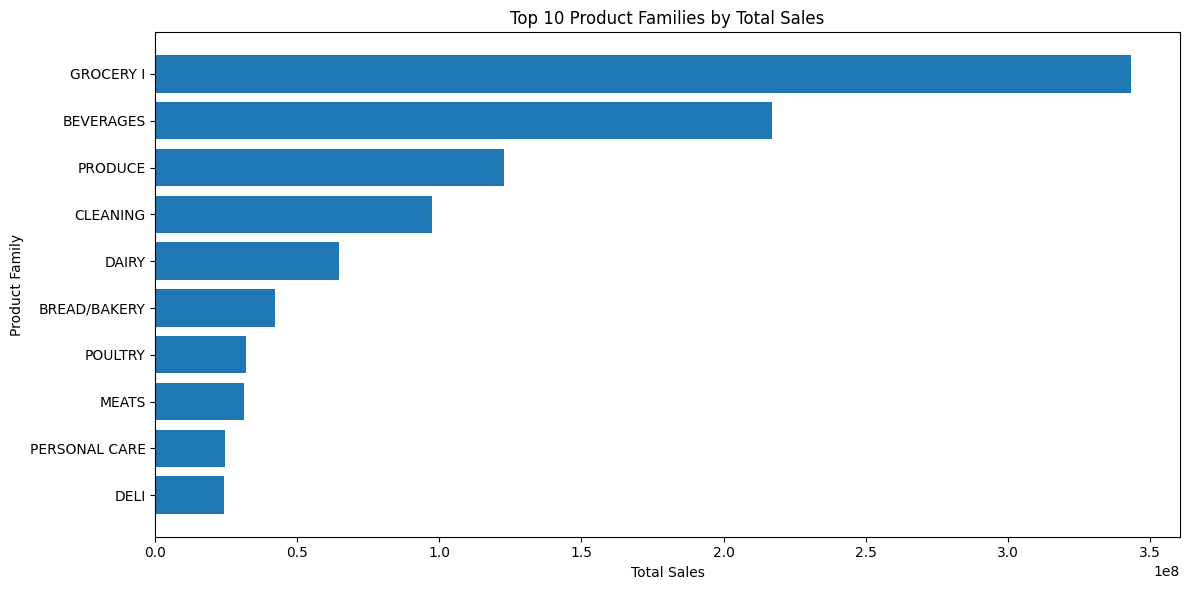

In [14]:
plt.figure(figsize=(12, 6))

plt.barh(
    family_sales.head(10)["family"],
    family_sales.head(10)["sales"]
)

plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [15]:
store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

store_sales.head(10)

,store_nbr,sales
0,44,6.208755e+07
1,45,5.449801e+07
2,47,5.094831e+07
3,3,5.048191e+07
4,49,4.342010e+07
5,46,4.189606e+07
6,48,3.593313e+07
7,51,3.291149e+07
8,8,3.049429e+07
9,50,2.865302e+07


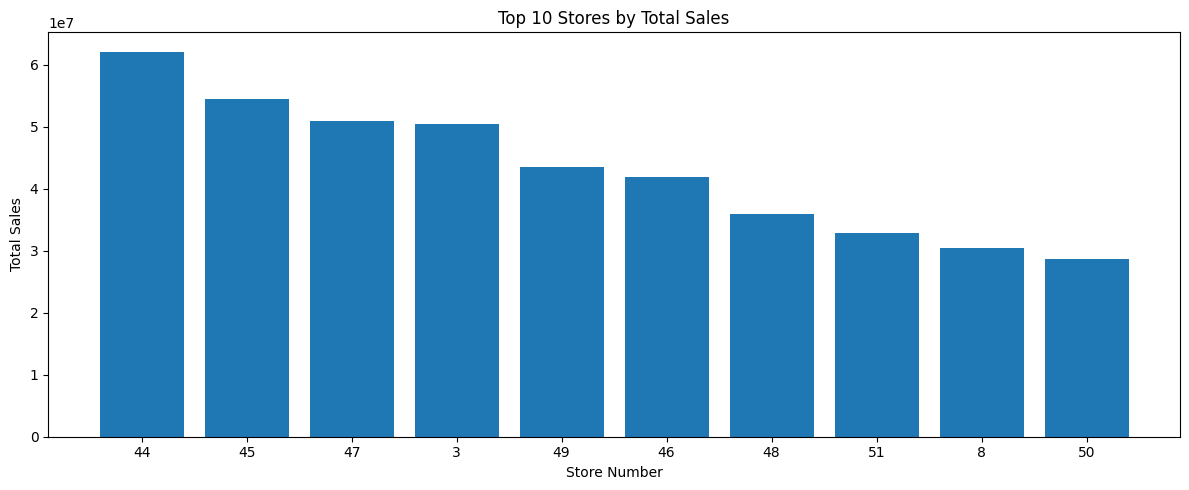

In [16]:
plt.figure(figsize=(12, 5))

plt.bar(
    store_sales.head(10)["store_nbr"].astype(str),
    store_sales.head(10)["sales"]
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store Number")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [17]:
train["day_name"] = train["date"].dt.day_name()

daily_sales = (
    train.groupby("day_name")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

daily_sales

day_name
Monday       346.544732
Tuesday      319.823843
Wednesday    332.909401
Thursday     283.540517
Friday       325.238138
Saturday     433.336472
Sunday       463.085366
Name: sales, dtype: float64

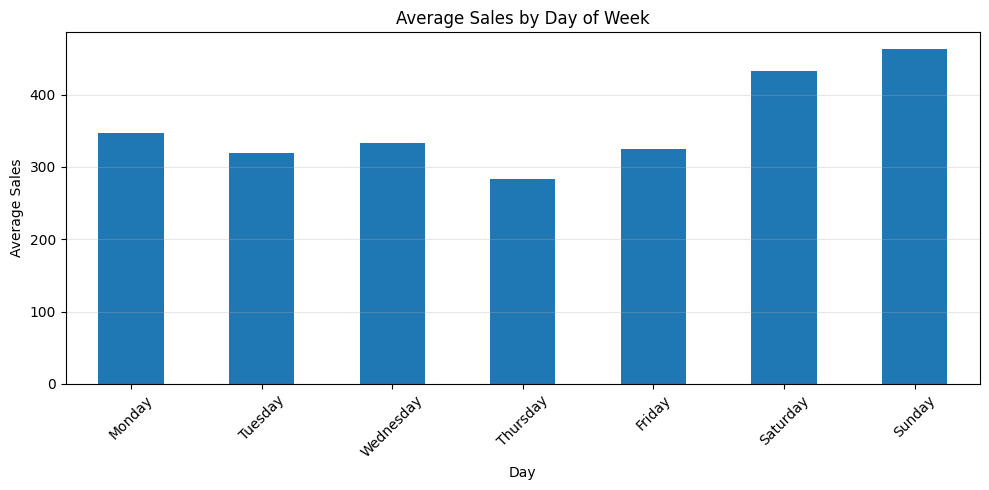

In [18]:
plt.figure(figsize=(10, 5))

daily_sales.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
monthly_average = (
    train.groupby(train["date"].dt.month)["sales"]
    .mean()
)

monthly_average.index = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_average

Jan    341.921554
Feb    320.928869
Mar    352.009294
Apr    339.199841
May    341.765820
Jun    353.597842
Jul    374.219111
Aug    336.992535
Sep    362.297418
Oct    362.407132
Nov    375.681762
Dec    453.740370
Name: sales, dtype: float64

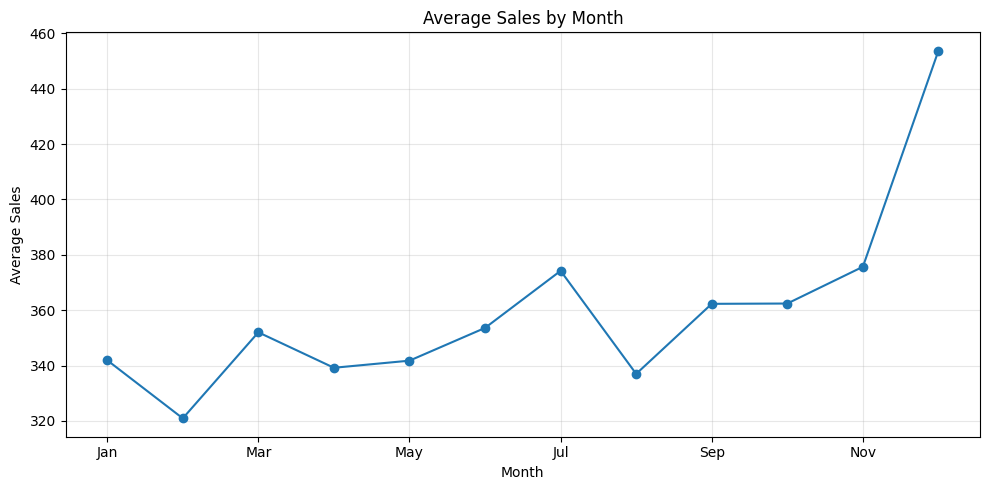

In [20]:
plt.figure(figsize=(10, 5))

monthly_average.plot(marker="o")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
daily_total = (
    train.groupby("date", as_index=False)["sales"]
    .sum()
)

daily_total["day_name"] = daily_total["date"].dt.day_name()
daily_total["month"] = daily_total["date"].dt.month

daily_total.head()

,date,sales,day_name,month
0,2013-01-01,2511.618999,Tuesday,1
1,2013-01-02,496092.417944,Wednesday,1
2,2013-01-03,361461.231124,Thursday,1
3,2013-01-04,354459.677093,Friday,1
4,2013-01-05,477350.121229,Saturday,1


In [22]:
weekday_total = (
    daily_total.groupby("day_name")["sales"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

weekday_total

day_name
Monday       617542.713052
Tuesday      569926.087922
Wednesday    593244.553472
Thursday     505269.201115
Friday       579574.361085
Saturday     772205.593943
Sunday       825218.121579
Name: sales, dtype: float64

In [23]:
monthly_total = (
    daily_total.groupby("month")["sales"]
    .mean()
)

monthly_total.index = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_total

Jan    609304.208495
Feb    571895.244225
Mar    627280.562239
Apr    604454.117050
May    609026.690473
Jun    630111.355279
Jul    666858.456059
Aug    600520.696680
Sep    645613.999338
Oct    645809.509319
Nov    669464.900519
Dec    808565.339708
Name: sales, dtype: float64

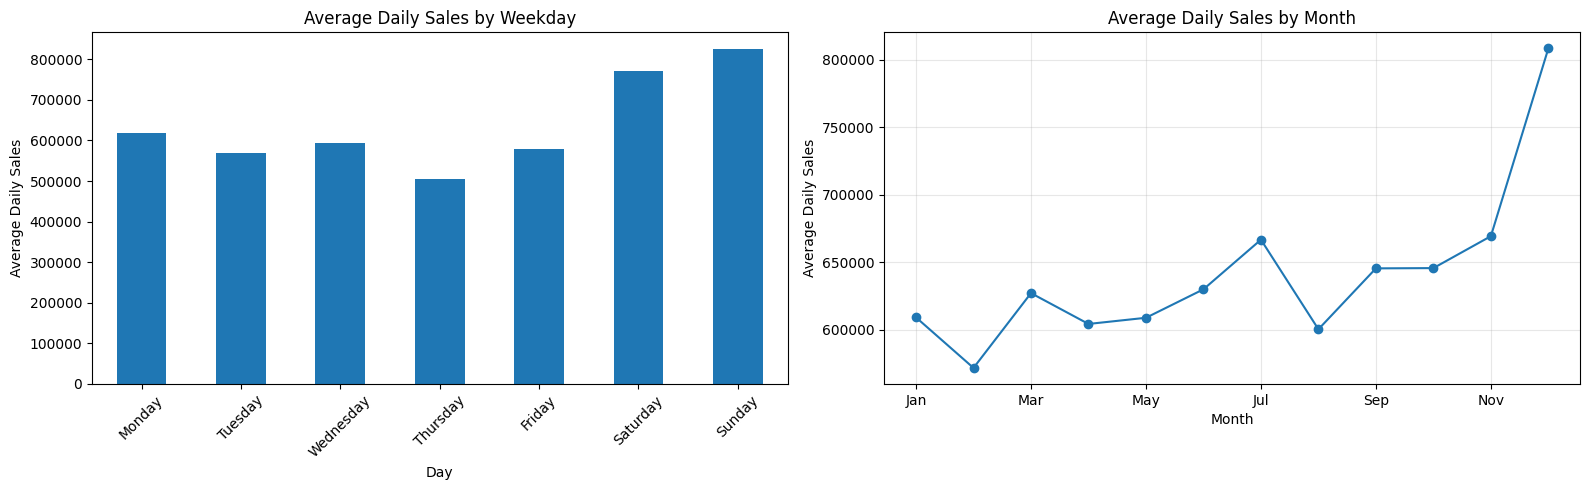

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

weekday_total.plot(
    kind="bar",
    ax=axes[0],
    title="Average Daily Sales by Weekday"
)

monthly_total.plot(
    marker="o",
    ax=axes[1],
    title="Average Daily Sales by Month"
)

axes[0].set_xlabel("Day")
axes[0].set_ylabel("Average Daily Sales")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Daily Sales")

axes[0].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
records_per_date = (
    train.groupby("date")
    .size()
)

records_per_date.describe()

count    1684.0
mean     1782.0
std         0.0
min      1782.0
25%      1782.0
50%      1782.0
75%      1782.0
max      1782.0
dtype: float64

In [26]:
records_per_date.sort_values().head(15)

date
2017-08-11    1782
2017-08-10    1782
2017-08-09    1782
2017-08-08    1782
2017-08-07    1782
2017-08-06    1782
2017-08-05    1782
2017-08-04    1782
2017-08-03    1782
2017-08-02    1782
2017-08-01    1782
2017-07-31    1782
2017-07-30    1782
2017-07-29    1782
2017-07-28    1782
dtype: int64

In [27]:
train.loc[
    train["date"] == "2013-01-01",
    ["store_nbr", "family", "sales"]
].sort_values("sales", ascending=False).head(20)

,store_nbr,family,sales
564,25,BEVERAGES,810.000000
573,25,GROCERY I,700.000000
568,25,CLEANING,186.000000
566,25,BREAD/BAKERY,180.589000
569,25,DAIRY,143.000000
585,25,MEATS,110.801000
583,25,"LIQUOR,WINE,BEER",105.000000
570,25,DELI,71.090000
571,25,EGGS,46.000000
589,25,POULTRY,42.637000


In [28]:
new_year = train[
    train["date"] == "2013-01-01"
]

print("Total records:", len(new_year))
print("Sales = 0:", (new_year["sales"] == 0).sum())
print("Sales > 0:", (new_year["sales"] > 0).sum())
print("Total sales:", new_year["sales"].sum())

Total records: 1782
Sales = 0: 1765
Sales > 0: 17
Total sales: 2511.6189990000003


In [29]:
transactions = pd.read_csv(
    DATA_DIR / "transactions.csv",
    parse_dates=["date"]
)

transactions[
    transactions["date"] == "2013-01-01"
]

,date,store_nbr,transactions
0,2013-01-01,25,770


In [30]:
holidays = pd.read_csv(
    DATA_DIR / "holidays_events.csv",
    parse_dates=["date"]
)

holidays[
    holidays["date"] == "2013-01-01"
]

,date,type,locale,locale_name,description,transferred
41,2013-01-01,Holiday,National,Ecuador,Primer dia del ano,False


In [31]:
holidays["date"] = pd.to_datetime(holidays["date"])

holiday_dates = holidays[
    holidays["transferred"] == False
]["date"].drop_duplicates()

daily_total["is_holiday"] = (
    daily_total["date"].isin(holiday_dates)
)

daily_total.head()

,date,sales,day_name,month,is_holiday
0,2013-01-01,2511.618999,Tuesday,1,True
1,2013-01-02,496092.417944,Wednesday,1,False
2,2013-01-03,361461.231124,Thursday,1,False
3,2013-01-04,354459.677093,Friday,1,False
4,2013-01-05,477350.121229,Saturday,1,True


In [32]:
holiday_sales = (
    daily_total.groupby("is_holiday")["sales"]
    .agg(["mean", "median", "count"])
)

holiday_sales.index = ["Normal Day", "Holiday"]

holiday_sales

,mean,median,count
Normal Day,627095.802719,624910.026095,1441
Holiday,699588.067841,685673.074740,243


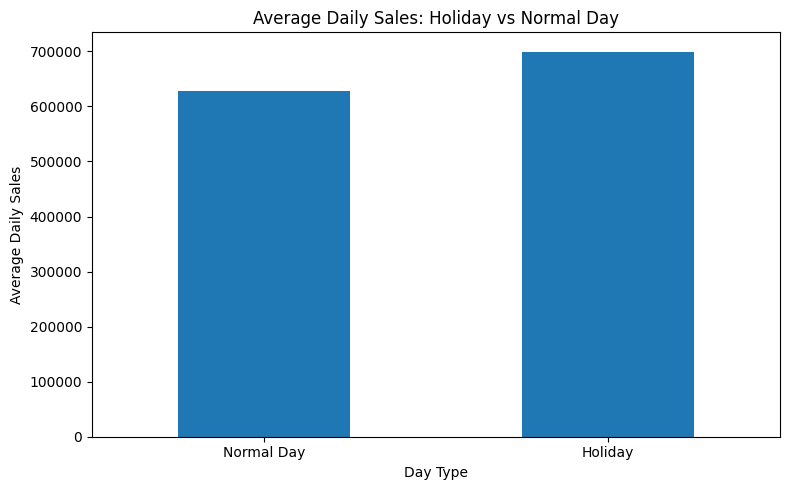

In [33]:
plt.figure(figsize=(8, 5))

holiday_sales["mean"].plot(kind="bar")

plt.title("Average Daily Sales: Holiday vs Normal Day")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [34]:
promotion_analysis = (
    train.assign(
        has_promotion=train["onpromotion"] > 0
    )
    .groupby("has_promotion")["sales"]
    .agg(["mean", "median", "count", "sum"])
)

promotion_analysis.index = [
    "No Promotion",
    "With Promotion"
]

promotion_analysis

,mean,median,count,sum
No Promotion,158.246681,3.0,2389559,3.781398e+08
With Promotion,1137.693730,373.0,611329,6.955052e+08


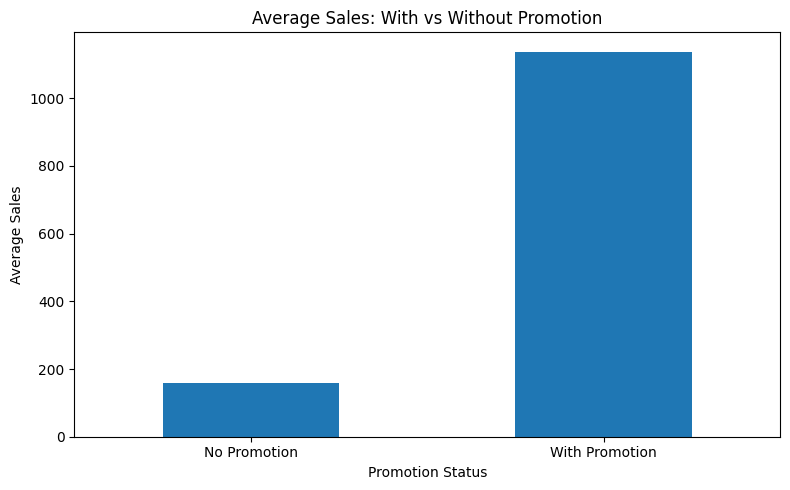

In [35]:
plt.figure(figsize=(8, 5))

promotion_analysis["mean"].plot(kind="bar")

plt.title("Average Sales: With vs Without Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [36]:
promotion_percentage = (
    (train["onpromotion"] > 0).mean() * 100
)

print(
    f"Records with promotion: {promotion_percentage:.2f}%"
)

Records with promotion: 20.37%


In [37]:
train["onpromotion"].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
)

count    3.000888e+06
mean     2.602770e+00
std      1.221888e+01
min      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
90%      4.000000e+00
95%      1.300000e+01
99%      5.500000e+01
max      7.410000e+02
Name: onpromotion, dtype: float64

In [38]:
import matplotlib.pyplot as plt

promotion_sales = (
    train.assign(
        promotion_group=pd.cut(
            train["onpromotion"],
            bins=[-1, 0, 5, 20, 50, float("inf")],
            labels=[
                "0",
                "1-5",
                "6-20",
                "21-50",
                ">50"
            ]
        )
    )
    .groupby("promotion_group", observed=False)["sales"]
    .agg(["mean", "median", "count"])
)

display(promotion_sales)

,mean,median,count
promotion_group,,,
0,158.246681,3.000,2389559
1-5,645.262500,211.303,355998
6-20,1254.364817,487.800,150471
21-50,2167.008534,1395.614,68589
>50,3540.418906,2839.000,36271


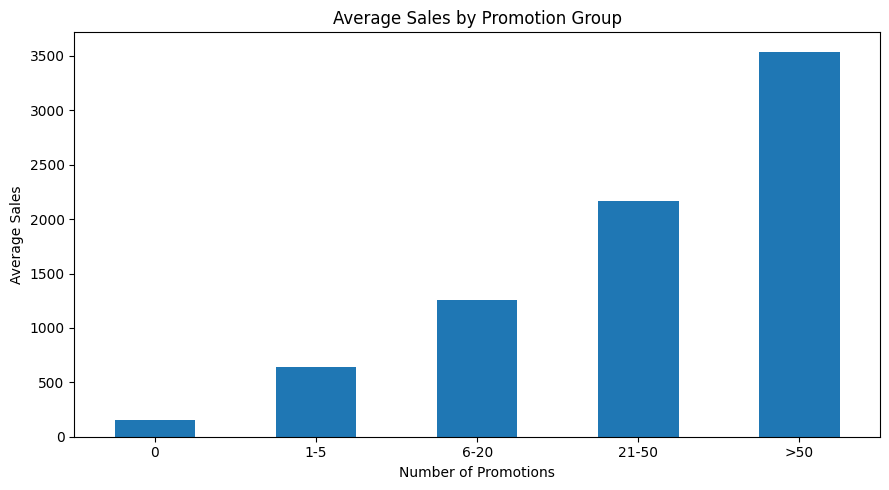

In [39]:
promotion_sales["mean"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Sales by Promotion Group",
    xlabel="Number of Promotions",
    ylabel="Average Sales"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

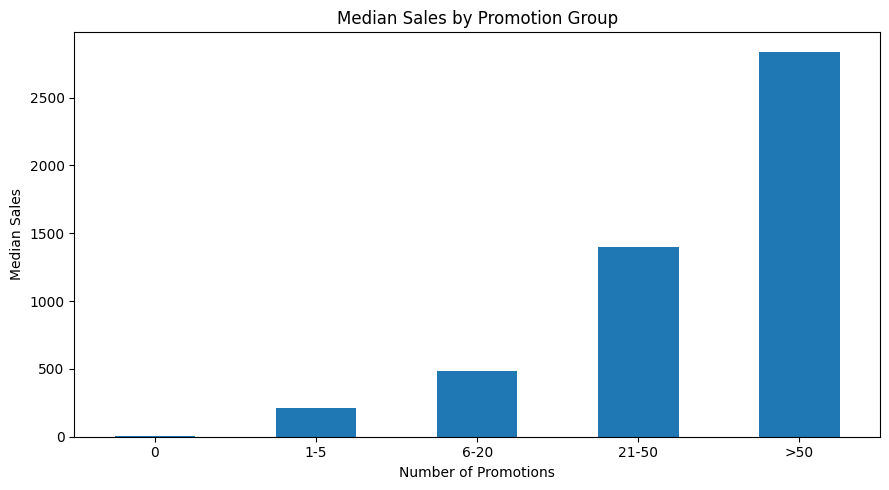

In [40]:
promotion_sales["median"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Median Sales by Promotion Group",
    xlabel="Number of Promotions",
    ylabel="Median Sales"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
family_analysis = (
    train.groupby("family")
    .agg(
        total_sales=("sales", "sum"),
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        total_records=("sales", "count"),
        avg_promotion=("onpromotion", "mean")
    )
    .sort_values("total_sales", ascending=False)
)

display(family_analysis)

,total_sales,mean_sales,median_sales,total_records,avg_promotion
family,,,,,
GROCERY I,3.434627e+08,3776.972100,3185.0000,90936,21.056578
BEVERAGES,2.169545e+08,2385.793151,1784.0000,90936,9.973586
PRODUCE,1.227047e+08,1349.352123,398.2905,90936,12.293492
CLEANING,9.752129e+07,1072.416744,938.0000,90936,7.270575
DAIRY,6.448771e+07,709.154889,520.0000,90936,8.013405
BREAD/BAKERY,4.213395e+07,463.336254,401.0000,90936,3.643101
POULTRY,3.187600e+07,350.532292,205.7430,90936,2.489894
MEATS,3.108647e+07,341.849965,224.9365,90936,3.343318
PERSONAL CARE,2.459205e+07,270.432513,222.0000,90936,2.715404


In [42]:
family_promotion = (
    train.assign(
        has_promotion=train["onpromotion"] > 0
    )
    .groupby(["family", "has_promotion"])
    .agg(
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        total_records=("sales", "count")
    )
    .reset_index()
)

family_promotion_pivot = family_promotion.pivot(
    index="family",
    columns="has_promotion",
    values="mean_sales"
)

family_promotion_pivot.columns = [
    "No Promotion",
    "With Promotion"
]

family_promotion_pivot["sales_difference"] = (
    family_promotion_pivot["With Promotion"]
    - family_promotion_pivot["No Promotion"]
)

family_promotion_pivot = family_promotion_pivot.sort_values(
    "sales_difference",
    ascending=False
)

display(family_promotion_pivot)

,No Promotion,With Promotion,sales_difference
family,,,
BEVERAGES,1292.272591,3215.498308,1923.225717
GROCERY I,2717.720813,4411.003431,1693.282618
PRODUCE,792.101911,2438.220197,1646.118286
DAIRY,479.811128,933.341720,453.530592
CLEANING,868.378326,1240.210741,371.832415
HOME CARE,101.956009,309.444864,207.488856
BREAD/BAKERY,379.513249,575.485296,195.972047
POULTRY,313.334513,485.006113,171.671600
MEATS,303.081088,467.301631,164.220543


In [43]:
family_promotion_pivot["relative_increase_pct"] = (
    (
        family_promotion_pivot["With Promotion"]
        - family_promotion_pivot["No Promotion"]
    )
    / family_promotion_pivot["No Promotion"]
) * 100

display(
    family_promotion_pivot.sort_values(
        "relative_increase_pct",
        ascending=False
    )
)

,No Promotion,With Promotion,sales_difference,relative_increase_pct
family,,,,
SCHOOL AND OFFICE SUPPLIES,1.022018,44.529107,43.507089,4256.977171
BABY CARE,0.109624,1.660377,1.550753,1414.604792
PET SUPPLIES,3.507379,15.835244,12.327865,351.483670
HOME AND KITCHEN II,10.275239,41.158133,30.882894,300.556454
PRODUCE,792.101911,2438.220197,1646.118286,207.816477
HOME APPLIANCES,0.456876,1.396552,0.939675,205.673959
LAWN AND GARDEN,5.510703,16.786862,11.276159,204.622872
HOME CARE,101.956009,309.444864,207.488856,203.508217
PLAYERS AND ELECTRONICS,6.081521,17.363958,11.282436,185.519972


In [44]:
display(
    family_promotion.pivot(
        index="family",
        columns="has_promotion",
        values="total_records"
    ).rename(
        columns={
            False: "No Promotion Records",
            True: "With Promotion Records"
        }
    ).sort_values(
        "With Promotion Records",
        ascending=False
    )
)

has_promotion,No Promotion Records,With Promotion Records
family,,
GROCERY I,34050.0,56886.0
BEVERAGES,39231.0,51705.0
CLEANING,41036.0,49900.0
DAIRY,44951.0,45985.0
DELI,51457.0,39479.0
BREAD/BAKERY,52040.0,38896.0
PERSONAL CARE,52705.0,38231.0
FROZEN FOODS,55116.0,35820.0
HOME CARE,58398.0,32538.0


In [45]:
promotion_counts = (
    family_promotion
    .pivot(
        index="family",
        columns="has_promotion",
        values="total_records"
    )
    .rename(columns={
        False: "no_promotion_records",
        True: "with_promotion_records"
    })
)

family_comparison = family_promotion_pivot.join(
    promotion_counts
)

reliable_comparison = family_comparison[
    (family_comparison["no_promotion_records"] >= 10000) &
    (family_comparison["with_promotion_records"] >= 10000)
].sort_values(
    "relative_increase_pct",
    ascending=False
)

display(reliable_comparison)

,No Promotion,With Promotion,sales_difference,relative_increase_pct,no_promotion_records,with_promotion_records
family,,,,,,
HOME AND KITCHEN II,10.275239,41.158133,30.882894,300.556454,71952.0,18984.0
PRODUCE,792.101911,2438.220197,1646.118286,207.816477,60152.0,30784.0
HOME CARE,101.956009,309.444864,207.488856,203.508217,58398.0,32538.0
BEAUTY,3.078452,8.291266,5.212813,169.332258,79819.0,11117.0
BEVERAGES,1292.272591,3215.498308,1923.225717,148.825080,39231.0,51705.0
HOME AND KITCHEN I,16.837739,39.460279,22.622540,134.356159,76334.0,14602.0
FROZEN FOODS,106.524349,228.997534,122.473185,114.972009,55116.0,35820.0
DAIRY,479.811128,933.341720,453.530592,94.522733,44951.0,45985.0
SEAFOOD,19.207320,35.433027,16.225707,84.476685,74370.0,16566.0


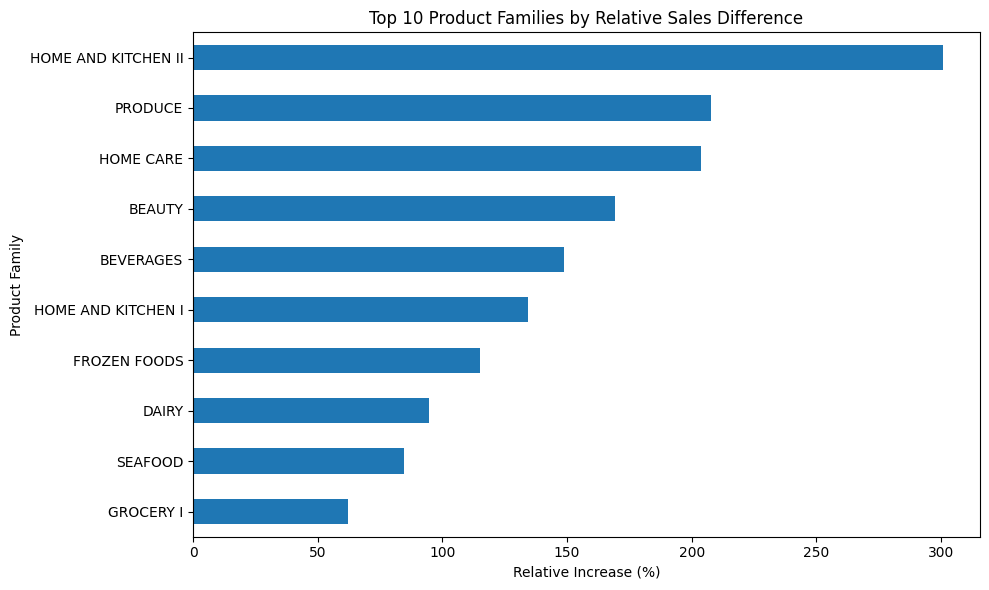

In [46]:
top_10 = reliable_comparison.head(10)

top_10["relative_increase_pct"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Families by Relative Sales Difference",
    xlabel="Relative Increase (%)",
    ylabel="Product Family"
)

plt.tight_layout()
plt.show()

# Store.csv

In [47]:
stores = pd.read_csv(DATA_DIR / "stores.csv")

display(stores.head())
stores.info()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   store_nbr  54 non-null     int64 
 1   city       54 non-null     object
 2   state      54 non-null     object
 3   type       54 non-null     object
 4   cluster    54 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 2.2+ KB


In [48]:
store_analysis = (
    train.groupby("store_nbr")
    .agg(
        total_sales=("sales", "sum"),
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        total_records=("sales", "count"),
        avg_promotion=("onpromotion", "mean")
    )
    .reset_index()
)

store_analysis = store_analysis.merge(
    stores,
    on="store_nbr",
    how="left"
)

store_analysis = store_analysis.sort_values(
    "total_sales",
    ascending=False
)

display(store_analysis.head(10))

,store_nbr,total_sales,mean_sales,median_sales,total_records,avg_promotion,city,state,type,cluster
43,44,6.208755e+07,1117.245254,75.0,55572,3.463057,Quito,Pichincha,A,5
44,45,5.449801e+07,980.673908,62.0,55572,3.446034,Quito,Pichincha,A,11
46,47,5.094831e+07,916.798209,51.0,55572,3.468023,Quito,Pichincha,A,14
2,3,5.048191e+07,908.405495,64.0,55572,3.186407,Quito,Pichincha,D,8
48,49,4.342010e+07,781.330450,48.0,55572,3.324264,Quito,Pichincha,A,11
45,46,4.189606e+07,753.905962,36.0,55572,3.431530,Quito,Pichincha,A,14
47,48,3.593313e+07,646.604950,30.0,55572,3.339200,Quito,Pichincha,A,14
50,51,3.291149e+07,592.231511,27.0,55572,2.925502,Guayaquil,Guayas,A,17
7,8,3.049429e+07,548.734739,39.0,55572,3.053174,Quito,Pichincha,D,8
49,50,2.865302e+07,515.601753,32.0,55572,3.133143,Ambato,Tungurahua,A,14


In [49]:
store_type_analysis = (
    store_analysis.groupby("type")
    .agg(
        total_sales=("total_sales", "sum"),
        mean_sales=("mean_sales", "mean"),
        avg_promotion=("avg_promotion", "mean"),
        total_stores=("store_nbr", "count")
    )
    .sort_values("total_sales", ascending=False)
)

display(store_type_analysis)

,total_sales,mean_sales,avg_promotion,total_stores
type,,,,
A,3.530438e+08,705.878743,3.009471,9
D,3.510833e+08,350.979407,2.698853,18
C,1.644347e+08,197.263301,2.090090,15
B,1.452606e+08,326.739714,2.838284,8
E,5.982244e+07,269.121301,2.706844,4


In [50]:
store_type_comparison = (
    store_analysis.groupby("type")
    .agg(
        total_sales=("total_sales", "sum"),
        avg_sales_per_store=("total_sales", "mean"),
        median_sales_per_store=("total_sales", "median"),
        avg_record_sales=("mean_sales", "mean"),
        total_stores=("store_nbr", "count")
    )
    .sort_values("avg_sales_per_store", ascending=False)
)

display(store_type_comparison)

,total_sales,avg_sales_per_store,median_sales_per_store,avg_record_sales,total_stores
type,,,,,
A,3.530438e+08,3.922709e+07,4.189606e+07,705.878743,9
D,3.510833e+08,1.950463e+07,1.888485e+07,350.979407,18
B,1.452606e+08,1.815758e+07,1.741880e+07,326.739714,8
E,5.982244e+07,1.495561e+07,1.585706e+07,269.121301,4
C,1.644347e+08,1.096232e+07,1.098641e+07,197.263301,15


In [51]:
city_analysis = (
    store_analysis.groupby("city")
    .agg(
        total_sales=("total_sales", "sum"),
        avg_sales_per_store=("total_sales", "mean"),
        total_stores=("store_nbr", "count")
    )
    .sort_values("total_sales", ascending=False)
)

display(city_analysis.head(10))

,total_sales,avg_sales_per_store,total_stores
city,,,
Quito,5.567418e+08,3.093010e+07,18
Guayaquil,1.229673e+08,1.537091e+07,8
Cuenca,4.916860e+07,1.638953e+07,3
Ambato,4.030440e+07,2.015220e+07,2
Santo Domingo,3.583432e+07,1.194477e+07,3
Machala,3.338680e+07,1.669340e+07,2
Cayambe,2.832556e+07,2.832556e+07,1
Latacunga,2.118226e+07,1.059113e+07,2
Daule,1.918802e+07,1.918802e+07,1


# transaksion & oil 

In [52]:
transactions = pd.read_csv(
    DATA_DIR / "transactions.csv",
    parse_dates=["date"]
)

display(transactions.head())
transactions.info()

display(
    transactions[["transactions"]].describe()
)

print("Date range:")
print(transactions["date"].min(), "to", transactions["date"].max())

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          83488 non-null  datetime64[ns]
 1   store_nbr     83488 non-null  int64         
 2   transactions  83488 non-null  int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 1.9 MB


,transactions
count,83488.000000
mean,1694.602158
std,963.286644
min,5.000000
25%,1046.000000
50%,1393.000000
75%,2079.000000
max,8359.000000


Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00


In [53]:
oil = pd.read_csv(
    DATA_DIR / "oil.csv",
    parse_dates=["date"]
)

display(oil.head())
oil.info()

display(
    oil[["dcoilwtico"]].describe()
)

print("Date range:")
print(oil["date"].min(), "to", oil["date"].max())

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[ns]
 1   dcoilwtico  1175 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.2 KB


,dcoilwtico
count,1175.000000
mean,67.714366
std,25.630476
min,26.190000
25%,46.405000
50%,53.190000
75%,95.660000
max,110.620000


Date range:
2013-01-01 00:00:00 to 2017-08-31 00:00:00


In [54]:
print("Jumlah toko:", transactions["store_nbr"].nunique())
print("Jumlah tanggal:", transactions["date"].nunique())

print(
    "Duplikasi kombinasi tanggal-toko:",
    transactions.duplicated(["date", "store_nbr"]).sum()
)

# Jumlah record transaksi per toko
transaction_coverage = (
    transactions.groupby("store_nbr")
    .agg(
        total_records=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
)

display(transaction_coverage)

Jumlah toko: 54
Jumlah tanggal: 1682
Duplikasi kombinasi tanggal-toko: 0


,total_records,first_date,last_date
store_nbr,,,
1,1676,2013-01-02,2017-08-15
2,1677,2013-01-02,2017-08-15
3,1676,2013-01-02,2017-08-15
4,1676,2013-01-02,2017-08-15
5,1677,2013-01-02,2017-08-15
6,1676,2013-01-02,2017-08-15
7,1675,2013-01-02,2017-08-15
8,1676,2013-01-02,2017-08-15
9,1676,2013-01-02,2017-08-15


In [55]:
oil_calendar = pd.date_range(
    start=oil["date"].min(),
    end=oil["date"].max(),
    freq="D"
)

oil_daily = (
    oil.set_index("date")
    .reindex(oil_calendar)
)

oil_daily.index.name = "date"

print("Total hari kalender:", len(oil_daily))
print("Tanggal tanpa record:", oil_daily["dcoilwtico"].isna().sum())

print(
    "Missing pada hari kerja:",
    oil_daily.loc[
        oil_daily.index.dayofweek < 5,
        "dcoilwtico"
    ].isna().sum()
)

print(
    "Missing pada akhir pekan:",
    oil_daily.loc[
        oil_daily.index.dayofweek >= 5,
        "dcoilwtico"
    ].isna().sum()
)

Total hari kalender: 1704
Tanggal tanpa record: 529
Missing pada hari kerja: 43
Missing pada akhir pekan: 486


In [56]:
# Pemeriksaan duplikasi
duplicate_count = transactions.duplicated(
    subset=["date", "store_nbr"]
).sum()

print("Duplicate date-store:", duplicate_count)

# Jumlah record per toko
transaction_coverage["missing_records"] = (
    (transactions["date"].max() - transactions["date"].min()).days + 1
    - transaction_coverage["total_records"]
)

display(
    transaction_coverage.sort_values(
        "total_records",
        ascending=True
    ).head(10)
)

Duplicate date-store: 0


,total_records,first_date,last_date,missing_records
store_nbr,,,,
52,118,2017-04-20,2017-08-15,1570
22,671,2015-10-09,2017-08-15,1017
42,720,2015-08-21,2017-08-15,968
21,748,2015-07-24,2017-08-15,940
29,874,2015-03-20,2017-08-15,814
20,909,2015-02-13,2017-08-15,779
53,1167,2014-05-29,2017-08-15,521
36,1551,2013-05-09,2017-08-15,137
18,1566,2013-01-02,2017-08-15,122


In [57]:
transaction_coverage["expected_records"] = (
    transactions["date"].max()
    - transaction_coverage["first_date"]
).dt.days + 1

transaction_coverage["missing_within_period"] = (
    transaction_coverage["expected_records"]
    - transaction_coverage["total_records"]
)

transaction_coverage["coverage_pct"] = (
    transaction_coverage["total_records"]
    / transaction_coverage["expected_records"]
) * 100

display(
    transaction_coverage.sort_values(
        "coverage_pct"
    )
)

,total_records,first_date,last_date,missing_records,expected_records,missing_within_period,coverage_pct
store_nbr,,,,,,,
18,1566,2013-01-02,2017-08-15,122,1687,121,92.827504
24,1577,2013-01-02,2017-08-15,111,1687,110,93.479549
25,1615,2013-01-01,2017-08-15,73,1688,73,95.675355
12,1616,2013-01-02,2017-08-15,72,1687,71,95.791346
14,1638,2013-01-02,2017-08-15,50,1687,49,97.095436
30,1655,2013-01-02,2017-08-15,33,1687,32,98.103142
43,1672,2013-01-02,2017-08-15,16,1687,15,99.110848
22,671,2015-10-09,2017-08-15,1017,677,6,99.113737
42,720,2015-08-21,2017-08-15,968,726,6,99.173554


In [58]:
print(
    "Duplicate date-store:",
    transactions.duplicated(
        subset=["date", "store_nbr"]
    ).sum()
)

Duplicate date-store: 0
